# Lab 03 · Will a station drain or fill? (classification)

**Roadmap P4.5 · Unit VI · CO4.** Each station-hour is labelled with a **regime**:
- **0 draining:** net flow below −τ × capacity;
- **1 stable:** otherwise;
- **2 filling:** net flow above +τ × capacity.

τ was chosen from the data, on the fit rows only, by `FeatureBuildJob`: the 70th percentile of
|net flow| / capacity. It is applied unchanged to September.

The classes are imbalanced (about 73 % stable), so accuracy flatters a model that always says "stable".
Models are therefore chosen on **macro-F1**, the mean of the three per-class F1 scores. It counts a missed
draining hour as much as a missed stable one. Every model is trained with **class weights** (inverse class
frequency, through `weightCol`), so the rare classes are not ignored.

The protocol is the one from Lab 02: train on 1–24 August, choose on 25–31 August, refit on August, report
September.

In [1]:
import matplotlib.pyplot as plt
from pyspark.ml import Pipeline
from pyspark.ml.classification import (
    DecisionTreeClassifier,
    LinearSVC,
    LogisticRegression,
    NaiveBayes,
    RandomForestClassifier,
)
from pyspark.ml.functions import vector_to_array
from pyspark.sql import functions as F

from velograph.common.serving import write_serving
from velograph.common.settings import data_paths
from velograph.lab import metrics
from velograph.lab.features import load_dictionary, load_splits, prep_stages
from velograph.lab.session import lab_session

SEED = 315
CLASSES = [0, 1, 2]
NAMES = {0: "draining", 1: "stable", 2: "filling"}
spark = lab_session("03-classification")
d = load_dictionary()
s = load_splits(spark)
print("Spark", spark.version, "·", spark.sparkContext.applicationId, "· tau =", d.tau)

Spark 3.5.8 · local-1792155946667 · tau = 0.05263


## 1. Class balance and weights

In [2]:
def balance(df):
    counts = {r["regime"]: r["count"] for r in df.groupBy("regime").count().collect()}  # bounded: 3 rows
    total = sum(counts.values())
    return {NAMES[c]: round(counts.get(c, 0) / total, 5) for c in CLASSES}, counts


def weighted(df):
    """Adds weight = n / (k * n_c): every class carries the same total weight in training."""
    _, counts = balance(df)
    n = sum(counts.values())
    pairs = [x for c in CLASSES for x in (F.lit(c), F.lit(n / (len(CLASSES) * counts[c])))]
    return df.withColumn("weight", F.create_map(*pairs)[F.col("regime")])


shares = {name: balance(df)[0] for name, df in (("train", s.train), ("test", s.test))}
train, fit = weighted(s.train), weighted(s.fit)
for name, b in shares.items():
    print(name, {k: f"{v * 100:.1f} %" for k, v in b.items()})

train {'draining': '13.8 %', 'stable': '72.5 %', 'filling': '13.7 %'}
test {'draining': '13.2 %', 'stable': '73.6 %', 'filling': '13.2 %'}


## 2. Baselines

- **Majority:** always "stable".
- **Seasonal naive:** the regime the hour-of-week profile implies, from the profile's expected net flow
  (mean arrivals − mean departures) against the same τ × capacity.

In [3]:
naive_net = (F.col("prof_arr_mean") - F.col("prof_dep_mean")) / F.col("capacity")
naive_regime = F.when(naive_net < -d.tau, 0).when(naive_net > d.tau, 2).otherwise(1)


def evaluate(pred):
    matrix = metrics.confusion(pred, "regime", CLASSES)
    return {**metrics.classification(matrix, CLASSES), "confusion": matrix}


baselines = {
    "majority": {
        "validation": evaluate(s.validation.withColumn("prediction", F.lit(1))),
        "test": evaluate(s.test.withColumn("prediction", F.lit(1))),
    },
    "seasonal-naive": {
        "validation": evaluate(s.validation.withColumn("prediction", naive_regime)),
        "test": evaluate(s.test.withColumn("prediction", naive_regime)),
    },
}
for name, m in baselines.items():
    print(
        f"{name:>15}: validation macro-F1 {m['validation']['macroF1']:.4f} · "
        f"test accuracy {m['test']['accuracy']:.4f} · test macro-F1 {m['test']['macroF1']:.4f}"
    )

       majority: validation macro-F1 0.2798 · test accuracy 0.7361 · test macro-F1 0.2827
 seasonal-naive: validation macro-F1 0.5040 · test accuracy 0.7388 · test macro-F1 0.5079


## 3. Candidates

Five algorithms from the syllabus:
- **multinomial logistic regression**;
- **decision tree** and **random forest**;
- **Gaussian naive Bayes**;
- **linear SVM**, which is binary, made three-class with **one-vs-rest**: one SVM per class, and the most
  confident one wins (written out below with built-in column functions).

Linear models and naive Bayes read one-hot categories; trees read the indices.

In [4]:
TREES = {"minInstancesPerNode": 20, "maxMemoryInMB": 1024, "cacheNodeIds": True, "seed": SEED}
ESTIMATORS = {
    "logistic-regression": (True, LogisticRegression, {"family": "multinomial", "maxIter": 100}),
    "decision-tree": (False, DecisionTreeClassifier, TREES),
    "random-forest": (False, RandomForestClassifier, {**TREES, "subsamplingRate": 0.5}),
    "naive-bayes": (True, NaiveBayes, {"modelType": "gaussian"}),
    "linear-svc-ovr": (True, LinearSVC, {"maxIter": 50}),
}
GRID = {
    "logistic-regression": [{"regParam": 0.0}, {"regParam": 0.01}],
    "decision-tree": [{"maxDepth": 8}, {"maxDepth": 12}],
    "random-forest": [{"numTrees": 30, "maxDepth": 12}],
    "naive-bayes": [{"smoothing": 1.0}],
    "linear-svc-ovr": [{"regParam": 0.01}],
}


class OneVsRestSVM:
    """One linear SVM per class, each answering "this class or not?"; the most confident one wins.

    Spark's OneVsRest does exactly this, but PySpark scores its model with Python UDFs, row by row in Python
    workers. Here the three margins are read from each SVM's raw prediction and compared with built-in column
    functions, so everything stays in the JVM.
    """

    def __init__(self, params):
        self.params = params

    def fit(self, df):
        prep = Pipeline(stages=prep_stages(d, linear=True)).fit(df)
        data = prep.transform(df)
        _, estimator, fixed = ESTIMATORS["linear-svc-ovr"]
        models = [
            estimator(
                featuresCol="features",
                labelCol="is_class",
                weightCol="weight",
                rawPredictionCol=f"raw_{c}",
                predictionCol=f"svm_{c}",
                **fixed,
                **self.params,
            ).fit(data.withColumn("is_class", (F.col("regime") == c).cast("double")))
            for c in CLASSES
        ]
        return FittedOneVsRest(prep, models)


class FittedOneVsRest:
    def __init__(self, prep, models):
        self.prep, self.models = prep, models

    def transform(self, df):
        out = self.prep.transform(df)
        for model in self.models:
            out = model.transform(out)
        margin = {
            c: vector_to_array(F.col(f"raw_{c}"))[1] for c in CLASSES
        }  # distance to that SVM's hyperplane
        best = F.greatest(*margin.values())
        return out.withColumn(
            "prediction", F.when(margin[0] == best, 0).when(margin[1] == best, 1).otherwise(2)
        )


def pipeline(algo, params):
    linear, estimator, fixed = ESTIMATORS[algo]
    if algo == "linear-svc-ovr":
        return OneVsRestSVM(params)
    model = estimator(featuresCol="features", labelCol="regime", weightCol="weight", **fixed, **params)
    return Pipeline(stages=[*prep_stages(d, linear=linear), model])


tuning = {algo: [] for algo in GRID}
for algo, grid in GRID.items():
    for params in grid:
        fitted = pipeline(algo, params).fit(train)
        m = evaluate(fitted.transform(s.validation))
        tuning[algo].append({"params": params, "validation": m})
        print(f"{algo:>20} {params}: validation macro-F1 {m['macroF1']:.4f} · accuracy {m['accuracy']:.4f}")
chosen = {
    algo: max(runs, key=lambda r: r["validation"]["macroF1"])["params"] for algo, runs in tuning.items()
}
print(chosen)

 logistic-regression {'regParam': 0.0}: validation macro-F1 0.5138 · accuracy 0.6240


 logistic-regression {'regParam': 0.01}: validation macro-F1 0.5084 · accuracy 0.6224


       decision-tree {'maxDepth': 8}: validation macro-F1 0.4939 · accuracy 0.5790


       decision-tree {'maxDepth': 12}: validation macro-F1 0.5095 · accuracy 0.6010


       random-forest {'numTrees': 30, 'maxDepth': 12}: validation macro-F1 0.5209 · accuracy 0.6151


         naive-bayes {'smoothing': 1.0}: validation macro-F1 0.4720 · accuracy 0.6576


      linear-svc-ovr {'regParam': 0.01}: validation macro-F1 0.5210 · accuracy 0.6496


{'logistic-regression': {'regParam': 0.0},
 'decision-tree': {'maxDepth': 12},
 'random-forest': {'numTrees': 30, 'maxDepth': 12},
 'naive-bayes': {'smoothing': 1.0},
 'linear-svc-ovr': {'regParam': 0.01}}


## 4. The leaderboard: refit on August, report September

In [5]:
leaderboard = []
for algo, params in chosen.items():
    validation = next(r["validation"] for r in tuning[algo] if r["params"] == params)
    test = evaluate(pipeline(algo, params).fit(fit).transform(s.test))
    leaderboard.append({"model": algo, "params": params, "validation": validation, "test": test})
    print(
        f"{algo:>20}: validation macro-F1 {validation['macroF1']:.4f} · "
        f"test macro-F1 {test['macroF1']:.4f} · test accuracy {test['accuracy']:.4f}"
    )
champion = max(leaderboard, key=lambda r: r["validation"]["macroF1"])
print("→ champion:", champion["model"], champion["params"])

 logistic-regression: validation macro-F1 0.5138 · test macro-F1 0.5127 · test accuracy 0.6369


       decision-tree: validation macro-F1 0.5095 · test macro-F1 0.5050 · test accuracy 0.6046


       random-forest: validation macro-F1 0.5209 · test macro-F1 0.5214 · test accuracy 0.6273


         naive-bayes: validation macro-F1 0.4720 · test macro-F1 0.4620 · test accuracy 0.6697


      linear-svc-ovr: validation macro-F1 0.5210 · test macro-F1 0.5188 · test accuracy 0.6585
→ champion: linear-svc-ovr {'regParam': 0.01}


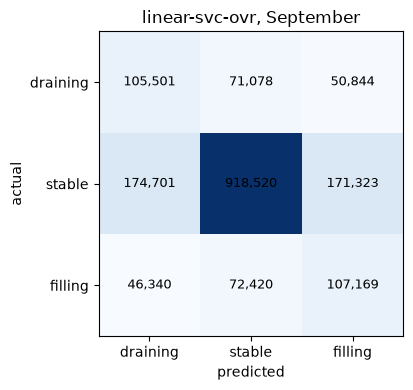

 draining: precision 0.323 · recall 0.464 · F1 0.381 · 227,423 hours
   stable: precision 0.865 · recall 0.726 · F1 0.790 · 1,264,544 hours
  filling: precision 0.325 · recall 0.474 · F1 0.386 · 225,929 hours


In [6]:
matrix = champion["test"]["confusion"]
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(matrix, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{matrix[i][j]:,}", ha="center", va="center", fontsize=9)
ax.set_xticks(range(3), [NAMES[c] for c in CLASSES])
ax.set_yticks(range(3), [NAMES[c] for c in CLASSES])
ax.set_xlabel("predicted")
ax.set_ylabel("actual")
ax.set_title(f"{champion['model']}, September")
plt.tight_layout()
plt.show()
for row in champion["test"]["perClass"]:
    print(
        f"{NAMES[row['class']]:>9}: precision {row['precision']:.3f} · recall {row['recall']:.3f} · "
        f"F1 {row['f1']:.3f} · {row['support']:,} hours"
    )

In [7]:
path = write_serving(
    data_paths().serving / "ml-classification.json",
    "ml-classification",
    "lab-03-classification",
    {
        "tau": d.tau,
        "tauQuantile": d.report["tauQuantile"],
        "classes": [{"id": c, "name": NAMES[c]} for c in CLASSES],
        "balance": shares,
        "weighting": "n / (k * n_class), computed on each training set",
        "selection": "highest validation macro-F1; September is reported only",
        "grid": GRID,
        "tuning": tuning,
        "fixedParams": {algo: fixed for algo, (_, _, fixed) in ESTIMATORS.items()},
        "baselines": baselines,
        "leaderboard": leaderboard,
        "champion": champion["model"],
    },
    rows=s.test.count(),
    source={"from": d.report["windows"][0]["profile"]["from"], "to": d.report["windows"][1]["rows"]["to"]},
)
print("wrote", path)

wrote C:\Users\Sayan\Desktop\int315\data\serving\ml-classification.json


In [8]:
spark.stop()